In [3]:
import os
import pandas as pd
from sqlalchemy import create_engine
import seaborn as sns
DATABASE_URL = os.getenv("DATABASE_URL")
engine = create_engine(DATABASE_URL)

query = """
SELECT 
    r.id AS room_id,
    r.price,
    r.floor,
    r.liv_area,
    r.floor_plan,
    b.id AS building_id,
    b.station_distance,
    b.age,
    b.total_floors,
    b.building_structure,
    b.address
FROM rooms r
JOIN buildings b ON r.building_id = b.id
WHERE r.price IS NOT NULL;
"""

df = pd.read_sql(query, engine)
print(f"Loaded {len(df)} rooms.")
df.head()

Loaded 2998 rooms.


,room_id,price,floor,liv_area,floor_plan,building_id,station_distance,age,total_floors,building_structure,address
0,1944,260000,1.0,55.37,1LDK,389,6,22,6,RC,東京都渋谷区西原1
1,1946,310000,4.0,65.25,2LDK,389,6,22,6,RC,東京都渋谷区西原1
2,603,88000,2.0,19.82,ワンルーム,145,3,33,10,鉄骨,東京都渋谷区恵比寿1
3,604,90000,2.0,19.82,ワンルーム,145,3,33,10,鉄骨,東京都渋谷区恵比寿1
4,605,90000,3.0,19.82,ワンルーム,145,3,33,10,鉄骨,東京都渋谷区恵比寿1


In [23]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2998 entries, 0 to 2997
Data columns (total 11 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   room_id             2998 non-null   int64  
 1   price               2998 non-null   int64  
 2   floor               2866 non-null   float64
 3   liv_area            2998 non-null   float64
 4   floor_plan          2998 non-null   object 
 5   building_id         2998 non-null   int64  
 6   station_distance    2998 non-null   int64  
 7   age                 2998 non-null   int64  
 8   total_floors        2998 non-null   int64  
 9   building_structure  2998 non-null   object 
 10  address             2998 non-null   object 
dtypes: float64(2), int64(6), object(3)
memory usage: 257.8+ KB


,room_id,price,floor,liv_area,building_id,station_distance,age,total_floors
count,2998.000000,2.998000e+03,2866.000000,2998.000000,2998.000000,2998.000000,2998.000000,2998.000000
mean,2659.844897,2.303916e+05,4.428821,39.111981,562.050033,6.632422,16.295864,7.781187
std,1840.763870,2.180535e+05,3.556769,23.178514,453.965487,3.017518,13.762180,5.116281
min,1.000000,3.500000e+04,1.000000,9.000000,1.000000,1.000000,0.000000,1.000000
25%,1117.250000,1.290000e+05,2.000000,24.485000,203.250000,4.000000,4.250000,4.000000
50%,2350.500000,1.820000e+05,3.000000,33.625000,420.500000,7.000000,15.000000,6.000000
75%,4095.750000,2.690000e+05,6.000000,46.077500,843.750000,8.000000,23.000000,11.000000
max,6836.000000,3.600000e+06,32.000000,268.450000,1924.000000,33.000000,73.000000,39.000000


findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Font family 'Noto Sans CJK JP' not found.
findfont: Fo

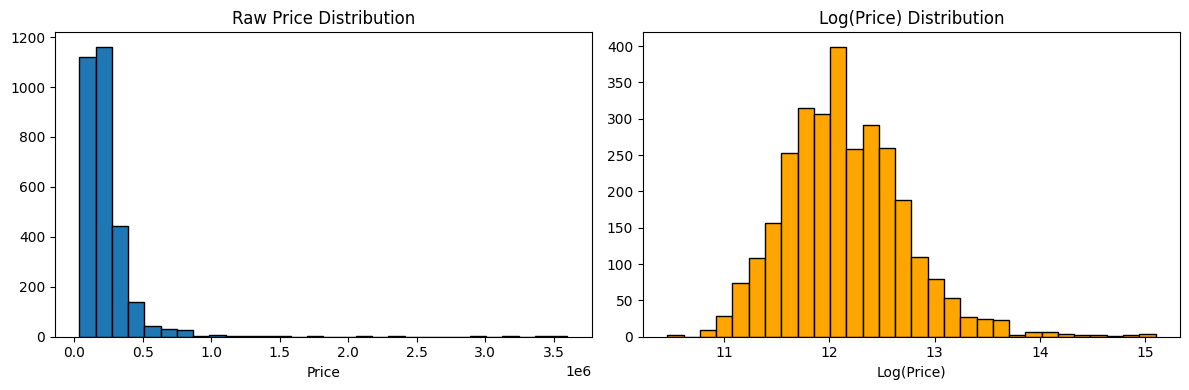

In [24]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# 生の家賃分布（右に裾が伸びているか確認）
axes[0].hist(df["price"], bins=30, edgecolor="black")
axes[0].set_title("Raw Price Distribution")
axes[0].set_xlabel("Price")

# 対数変換後の家賃分布（正規分布に近づくか確認）
axes[1].hist(np.log(df["price"]), bins=30, edgecolor="black", color="orange")
axes[1].set_title("Log(Price) Distribution")
axes[1].set_xlabel("Log(Price)")

plt.tight_layout()
plt.show()

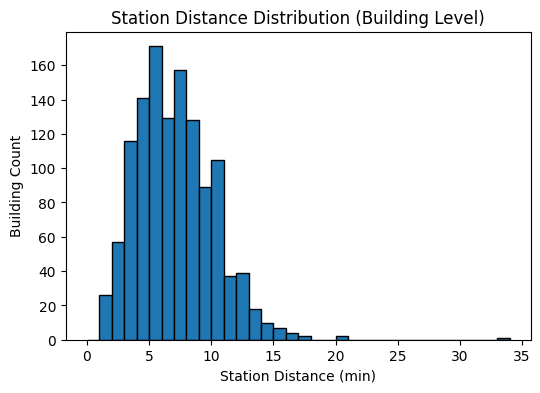

対象建物数: 1239棟
徒歩5分以内の建物割合: 41.2%
徒歩10分以内の建物割合: 90.3%


In [20]:
b_station_dist = df.drop_duplicates(subset=["building_id"])["station_distance"].dropna()

# ヒストグラム描画
plt.figure(figsize=(6, 4))
plt.hist(
    b_station_dist, 
    bins=range(0, int(b_station_dist.max()) + 2), 
    edgecolor="black"
)
plt.title("Station Distance Distribution (Building Level)")
plt.xlabel("Station Distance (min)")
plt.ylabel("Building Count")
plt.show()

# 建物ベースでの累積割合
print(f"対象建物数: {len(b_station_dist)}棟")
print(f"徒歩5分以内の建物割合: {(b_station_dist <= 5).mean():.1%}")
print(f"徒歩10分以内の建物割合: {(b_station_dist <= 10).mean():.1%}")

抽出された上位6町名（件数）:
  Yoyogi (代々木): 364件
  Honmachi (本町): 358件
  Sasazuka (笹塚): 251件
  Ebisu (恵比寿): 231件
  Hiroo (広尾): 182件
  Hatagaya (幡ヶ谷): 176件


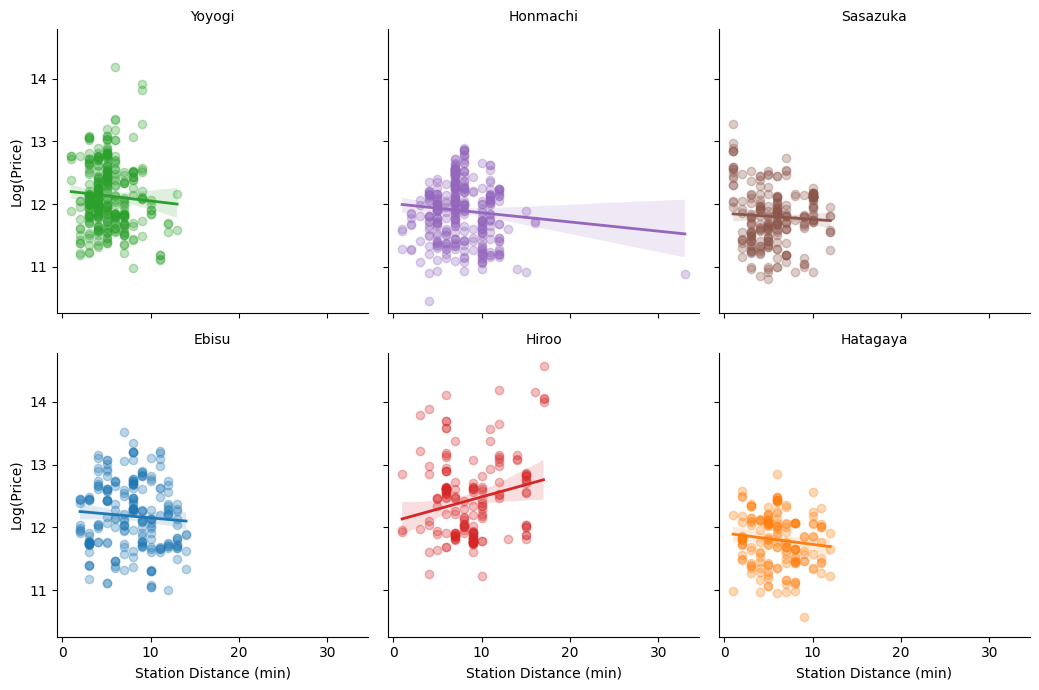

In [12]:
import re
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# 1. 前処理: フル住所から町名を抽出し、対数家賃を計算
def extract_town(addr):
    if not isinstance(addr, str):
        return "Unknown"
    match = re.search(r"渋谷区([^\d０-９丁目番]+)", addr)
    return match.group(1) if match else addr

df["town"] = df["address"].apply(extract_town)
df["log_price"] = np.log(df["price"])

# 2. 上位6町名の抽出とローマ字マッピング
top_6_towns = df["town"].value_counts().head(6).index.tolist()

town_map_en = {
    "代々木": "Yoyogi",
    "本町": "Honmachi",
    "笹塚": "Sasazuka",
    "恵比寿": "Ebisu",
    "広尾": "Hiroo",
    "幡ヶ谷": "Hatagaya"
}

df_top = df[df["town"].isin(top_6_towns)].copy()
df_top["town_en"] = df_top["town"].map(town_map_en).fillna(df_top["town"])

# 出現頻度順にプロット順序を固定
order_en = [town_map_en.get(t, t) for t in top_6_towns]

print("抽出された上位6町名（件数）:")
for t in top_6_towns:
    print(f"  {town_map_en.get(t, t)} ({t}): {(df['town'] == t).sum()}件")

# 3. プロット実行
g = sns.lmplot(
    data=df_top,
    x="station_distance",
    y="log_price",
    hue="town_en",
    col="town_en",
    col_order=order_en,
    col_wrap=3,
    height=3.5,
    scatter_kws={"alpha": 0.3},
    line_kws={"linewidth": 2}
)
g.set_axis_labels("Station Distance (min)", "Log(Price)")
g.set_titles(col_template="{col_name}")
plt.tight_layout()
g.savefig("../docs/images/phase3_graph1.png", dpi=150, bbox_inches="tight")
plt.show()

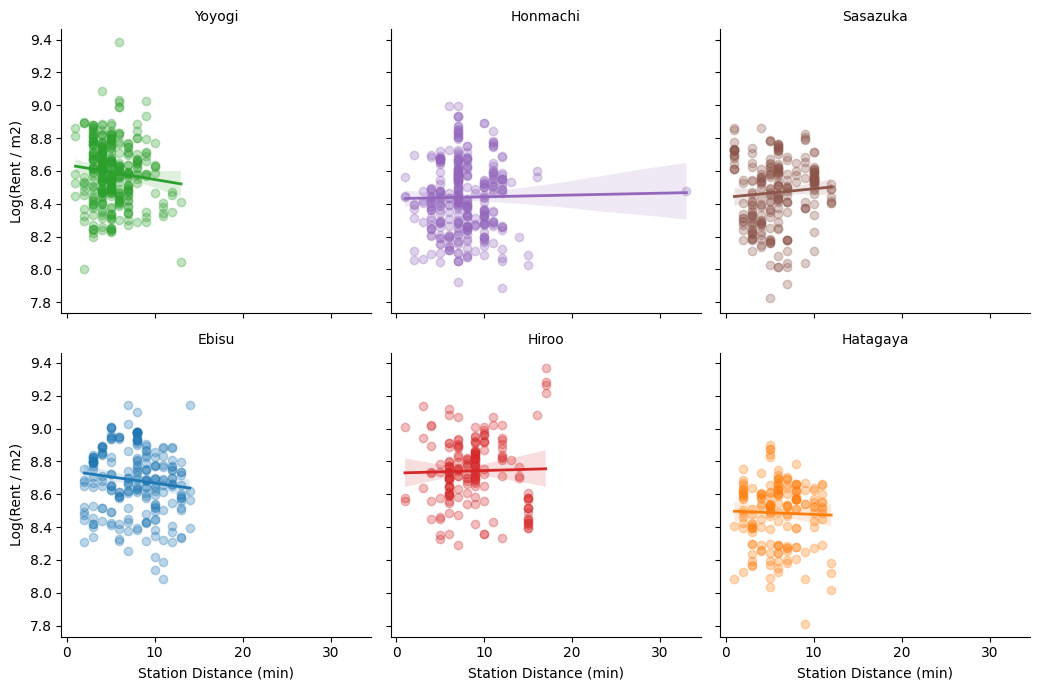

In [11]:
import re


# 1. 住所から町名を抽出
def extract_town(addr):
    if not isinstance(addr, str):
        return "Unknown"
    match = re.search(r"渋谷区([^\d０-９丁目番]+)", addr)
    return match.group(1) if match else addr

df["town"] = df["address"].apply(extract_town)

# 2. 変数の作成（対数家賃、平米単価の対数）
df["log_price"] = np.log(df["price"])
df["log_rent_per_m2"] = np.log(df["price"] / df["liv_area"])

# 3. 上位6町名を抽出してローマ字にマッピング
town_map_en = {
    "代々木": "Yoyogi",
    "本町": "Honmachi",
    "笹塚": "Sasazuka",
    "恵比寿": "Ebisu",
    "広尾": "Hiroo",
    "幡ヶ谷": "Hatagaya"
}

top_towns_jp = list(town_map_en.keys())
df_plot = df[df["town"].isin(top_towns_jp)].copy()
df_plot["town_en"] = df_plot["town"].map(town_map_en)
order_en = ["Yoyogi", "Honmachi", "Sasazuka", "Ebisu", "Hiroo", "Hatagaya"]

# 4. プロット実行（平米単価 vs 駅徒歩距離）
g = sns.lmplot(
    data=df_plot,
    x="station_distance",
    y="log_rent_per_m2",
    hue="town_en",
    col="town_en",
    col_order=order_en,
    col_wrap=3,
    height=3.5,
    scatter_kws={"alpha": 0.3},
    line_kws={"linewidth": 2}
)

g.set_axis_labels("Station Distance (min)", "Log(Rent / m2)")
g.set_titles(col_template="{col_name}")
plt.tight_layout()
g.savefig("../docs/images/phase3_graph2.png", dpi=150, bbox_inches="tight")
plt.show()

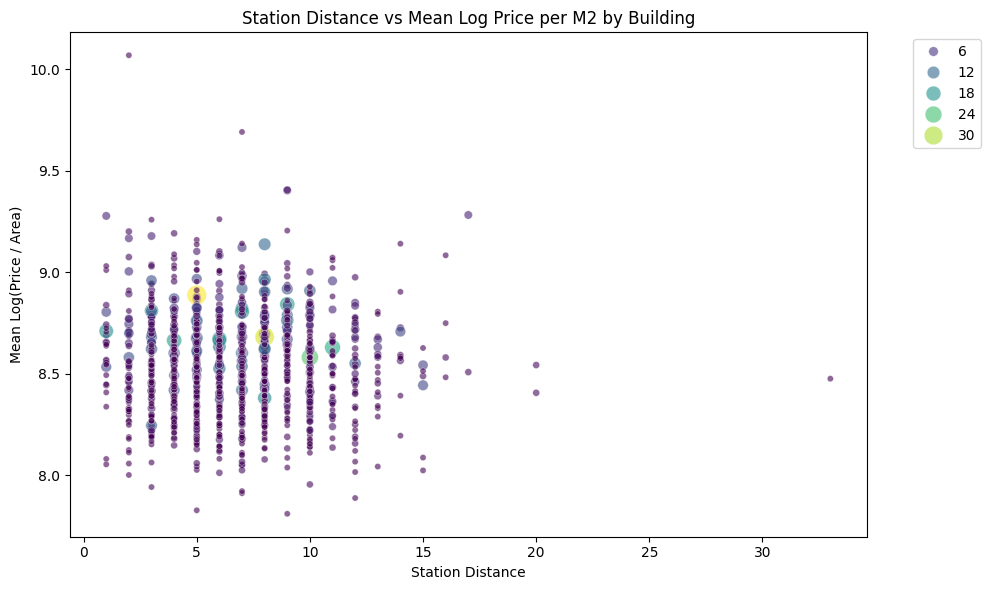

In [5]:
import numpy as np
import matplotlib.pyplot as plt
df['log_price_per_m2'] = np.log(df['price'] / df['liv_area'])

agg_df = (
    df.groupby(['building_id', 'station_distance'])
    .agg(
        mean_log_price_per_m2=('log_price_per_m2', 'mean'),
        room_count=('room_id', 'count')
    )
    .reset_index()
)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=agg_df,
    x='station_distance',
    y='mean_log_price_per_m2',
    size='room_count',  # 部屋数をプロットのサイズに反映（任意）
    sizes=(20, 200),
    alpha=0.6,
    hue='room_count',
    palette='viridis'
)
plt.title('Station Distance vs Mean Log Price per M2 by Building')
plt.xlabel('Station Distance')
plt.ylabel('Mean Log(Price / Area)')
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

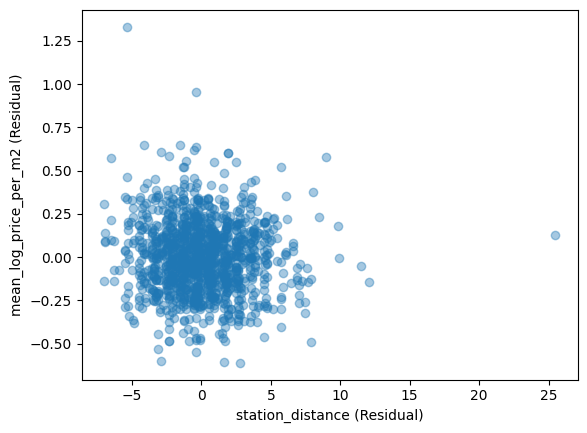

In [18]:
import statsmodels.formula.api as smf
import re


# 1. 住所から町名を抽出
def extract_town(addr):
    if not isinstance(addr, str):
        return "Unknown"
    match = re.search(r"渋谷区([^\d０-９丁目番]+)", addr)
    return match.group(1) if match else addr

df["area_group"] = df["address"].apply(extract_town)

# area_group がまだ agg_df になければマージする
if "area_group" not in agg_df.columns:
    agg_df = agg_df.merge(
        df[["building_id", "area_group"]].drop_duplicates(),
        on="building_id",
        how="left"
    )

resid_x = smf.ols("station_distance ~ C(area_group)", data=agg_df).fit().resid
resid_y = smf.ols("mean_log_price_per_m2 ~ C(area_group)", data=agg_df).fit().resid

plt.scatter(resid_x, resid_y, alpha=0.4)
plt.xlabel("station_distance (Residual)") #町効果を除いた残差
plt.ylabel("mean_log_price_per_m2 (Residual)") #町効果固定を除いた残差

# plt.show() の前に保存
plt.savefig("../docs/images/phase3_graph3.png", dpi=150, bbox_inches="tight")

# 画面表示
plt.show()

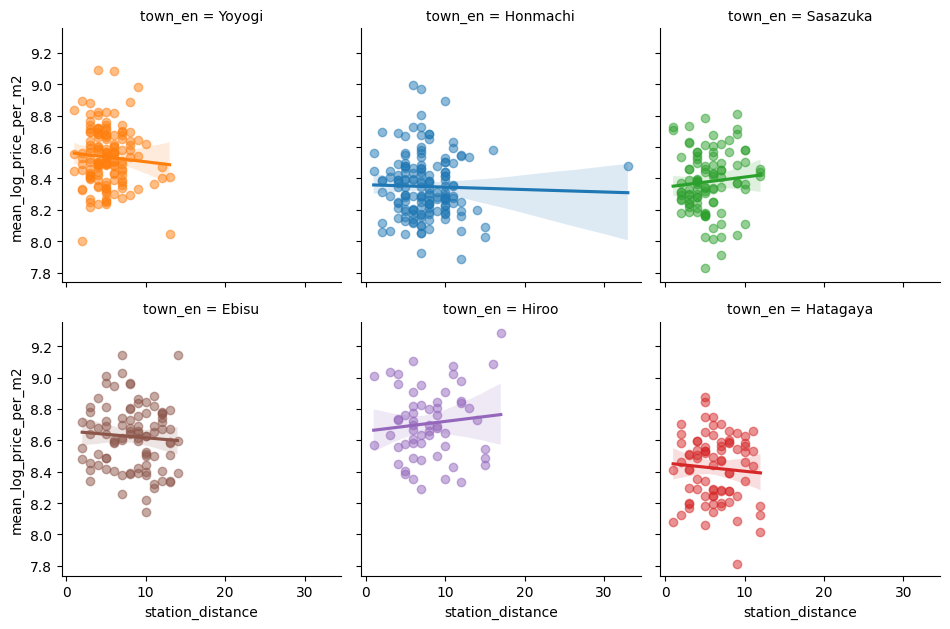

In [ ]:
top_towns = agg_df["area_group"].value_counts().head(6).index.tolist()
# g = sns.lmplot(
#     data=agg_top,
#     x="station_distance",
#     y="mean_log_price_per_m2",
#     hue="area_group",
#     col="area_group",
#     col_wrap=3,
#     height=3.2,
#     scatter_kws={"alpha": 0.5},
# )

order_en = ["Yoyogi", "Honmachi", "Sasazuka", "Ebisu", "Hiroo", "Hatagaya"]

agg_df["town_en"] = agg_df["area_group"].map(town_map_en)
agg_top = agg_df[agg_df["town_en"].isin(order_en)].copy()

g = sns.lmplot(
    data=agg_top,
    x="station_distance",
    y="mean_log_price_per_m2",
    hue="town_en",
    col="town_en",
    col_order=order_en,
    col_wrap=3,
    height=3.2,
    scatter_kws={"alpha": 0.5},
)

# plt.savefig("../docs/images/phase3_graph4.png", dpi=150, bbox_inches="tight")

# 画面表示
plt.show()